<a href="https://colab.research.google.com/github/dshukla1410/dshukla1410.github.io/blob/main/Nov4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
import pandas as pd

url = 'https://gdc-hub.s3.us-east-1.amazonaws.com/download/TCGA-BRCA.somaticmutation_wxs.tsv.gz'


try:
    print("Downloading and loading dataset from S3...")
    # pandas can read gzipped tab-separated files directly from a URL
    df = pd.read_csv(url, sep='\t', compression='gzip')
    print(f"Successfully loaded dataset! Shape: {df.shape}")
    display(df.head())
except Exception as e:
    print(f"An error occurred: {e}")

Successfully loaded dataset! Shape: (89569, 12)


,sample,gene,chrom,start,end,ref,alt,Tumor_Sample_Barcode,Amino_Acid_Change,effect,callers,dna_vaf
0,TCGA-A1-A0SO-01A,MIB2,chr1,1625276,1625299,CCCTCCGCAGGCAAGCCGGCGGAG,-,TCGA-A1-A0SO-01A-22D-A099-09,p.X356_splice,splice_acceptor_variant;coding_sequence_varian...,mutect2;varscan2,0.300000
1,TCGA-A1-A0SO-01A,VPS13D,chr1,12283654,12283654,T,C,TCGA-A1-A0SO-01A-22D-A099-09,p.I1851T,missense_variant,muse;mutect2;varscan2,0.179775
2,TCGA-A1-A0SO-01A,PRAMEF8,chr1,13281907,13281907,C,A,TCGA-A1-A0SO-01A-22D-A099-09,p.V297F,missense_variant,muse;mutect2,0.031496
3,TCGA-A1-A0SO-01A,NBPF1,chr1,16576355,16576355,C,G,TCGA-A1-A0SO-01A-22D-A099-09,p.E677D,missense_variant,muse;mutect2,0.086957
4,TCGA-A1-A0SO-01A,SRSF4,chr1,29148880,29148880,C,T,TCGA-A1-A0SO-01A-22D-A099-09,p.G339S,missense_variant,muse;mutect2;varscan2,0.134615


In [9]:
TCGA_BRCA = df
display(TCGA_BRCA.head())

,sample,gene,chrom,start,end,ref,alt,Tumor_Sample_Barcode,Amino_Acid_Change,effect,callers,dna_vaf
0,TCGA-A1-A0SO-01A,MIB2,chr1,1625276,1625299,CCCTCCGCAGGCAAGCCGGCGGAG,-,TCGA-A1-A0SO-01A-22D-A099-09,p.X356_splice,splice_acceptor_variant;coding_sequence_varian...,mutect2;varscan2,0.300000
1,TCGA-A1-A0SO-01A,VPS13D,chr1,12283654,12283654,T,C,TCGA-A1-A0SO-01A-22D-A099-09,p.I1851T,missense_variant,muse;mutect2;varscan2,0.179775
2,TCGA-A1-A0SO-01A,PRAMEF8,chr1,13281907,13281907,C,A,TCGA-A1-A0SO-01A-22D-A099-09,p.V297F,missense_variant,muse;mutect2,0.031496
3,TCGA-A1-A0SO-01A,NBPF1,chr1,16576355,16576355,C,G,TCGA-A1-A0SO-01A-22D-A099-09,p.E677D,missense_variant,muse;mutect2,0.086957
4,TCGA-A1-A0SO-01A,SRSF4,chr1,29148880,29148880,C,T,TCGA-A1-A0SO-01A-22D-A099-09,p.G339S,missense_variant,muse;mutect2;varscan2,0.134615


In [10]:
unique_samples_count = TCGA_BRCA['sample'].nunique()
print(f"Total number of unique samples: {unique_samples_count}")

Total number of unique samples: 986


In [11]:
TCGA_BRCA.shape

(89569, 12)

In [12]:
unique_genes_count = TCGA_BRCA['gene'].nunique()
print(f"Total number of unique mutated genes: {unique_genes_count}")

Total number of unique mutated genes: 16662


/tmp/ipykernel_1073/3273896030.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_20_genes, x='mutation_count', y='gene', palette='viridis')


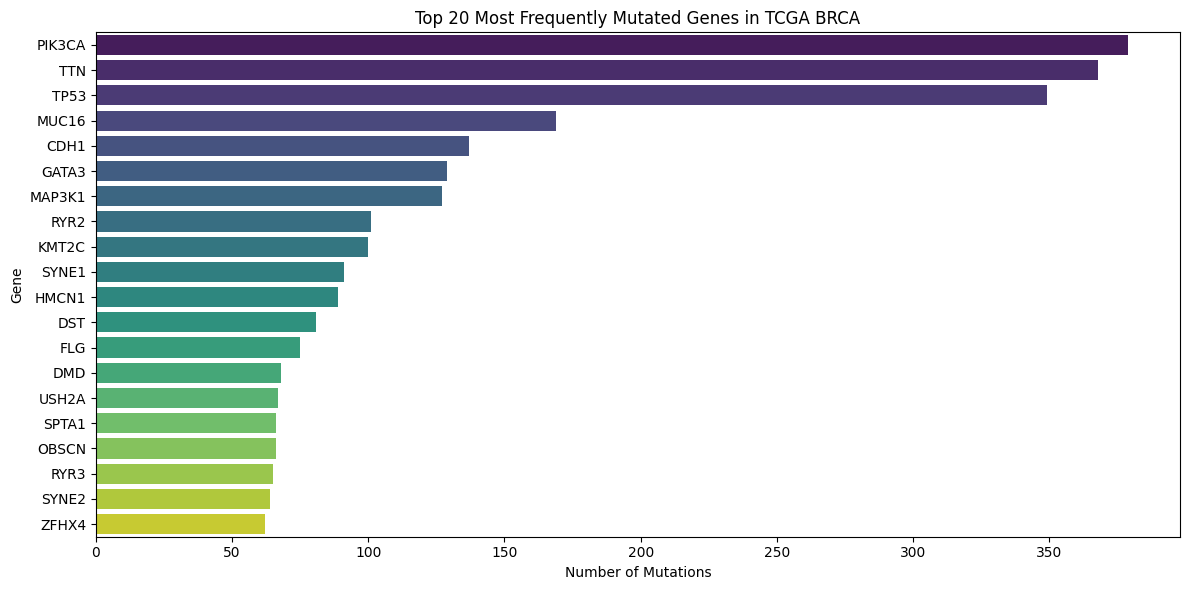

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

gene_mutation_counts = TCGA_BRCA['gene'].value_counts().reset_index()
gene_mutation_counts.columns = ['gene', 'mutation_count']


top_20_genes = gene_mutation_counts.head(20)


plt.figure(figsize=(12, 6))
sns.barplot(data=top_20_genes, x='mutation_count', y='gene', palette='viridis')
plt.title('Top 20 Most Frequently Mutated Genes in TCGA BRCA')
plt.xlabel('Number of Mutations')
plt.ylabel('Gene')
plt.tight_layout()
plt.show()

,mutation_type,count,percentage
0,missense_variant,54319,60.645543
1,synonymous_variant,19614,21.898446
2,stop_gained,4733,5.284253
3,frameshift_variant,4126,4.606556
4,missense_variant;splice_region_variant,1588,1.772955
...,...,...,...
65,frameshift_variant;start_lost;splice_region_va...,1,0.001116
66,start_lost;start_retained_variant;5_prime_UTR_...,1,0.001116
67,intron_variant;NMD_transcript_variant,1,0.001116
68,splice_donor_variant;coding_sequence_variant;i...,1,0.001116


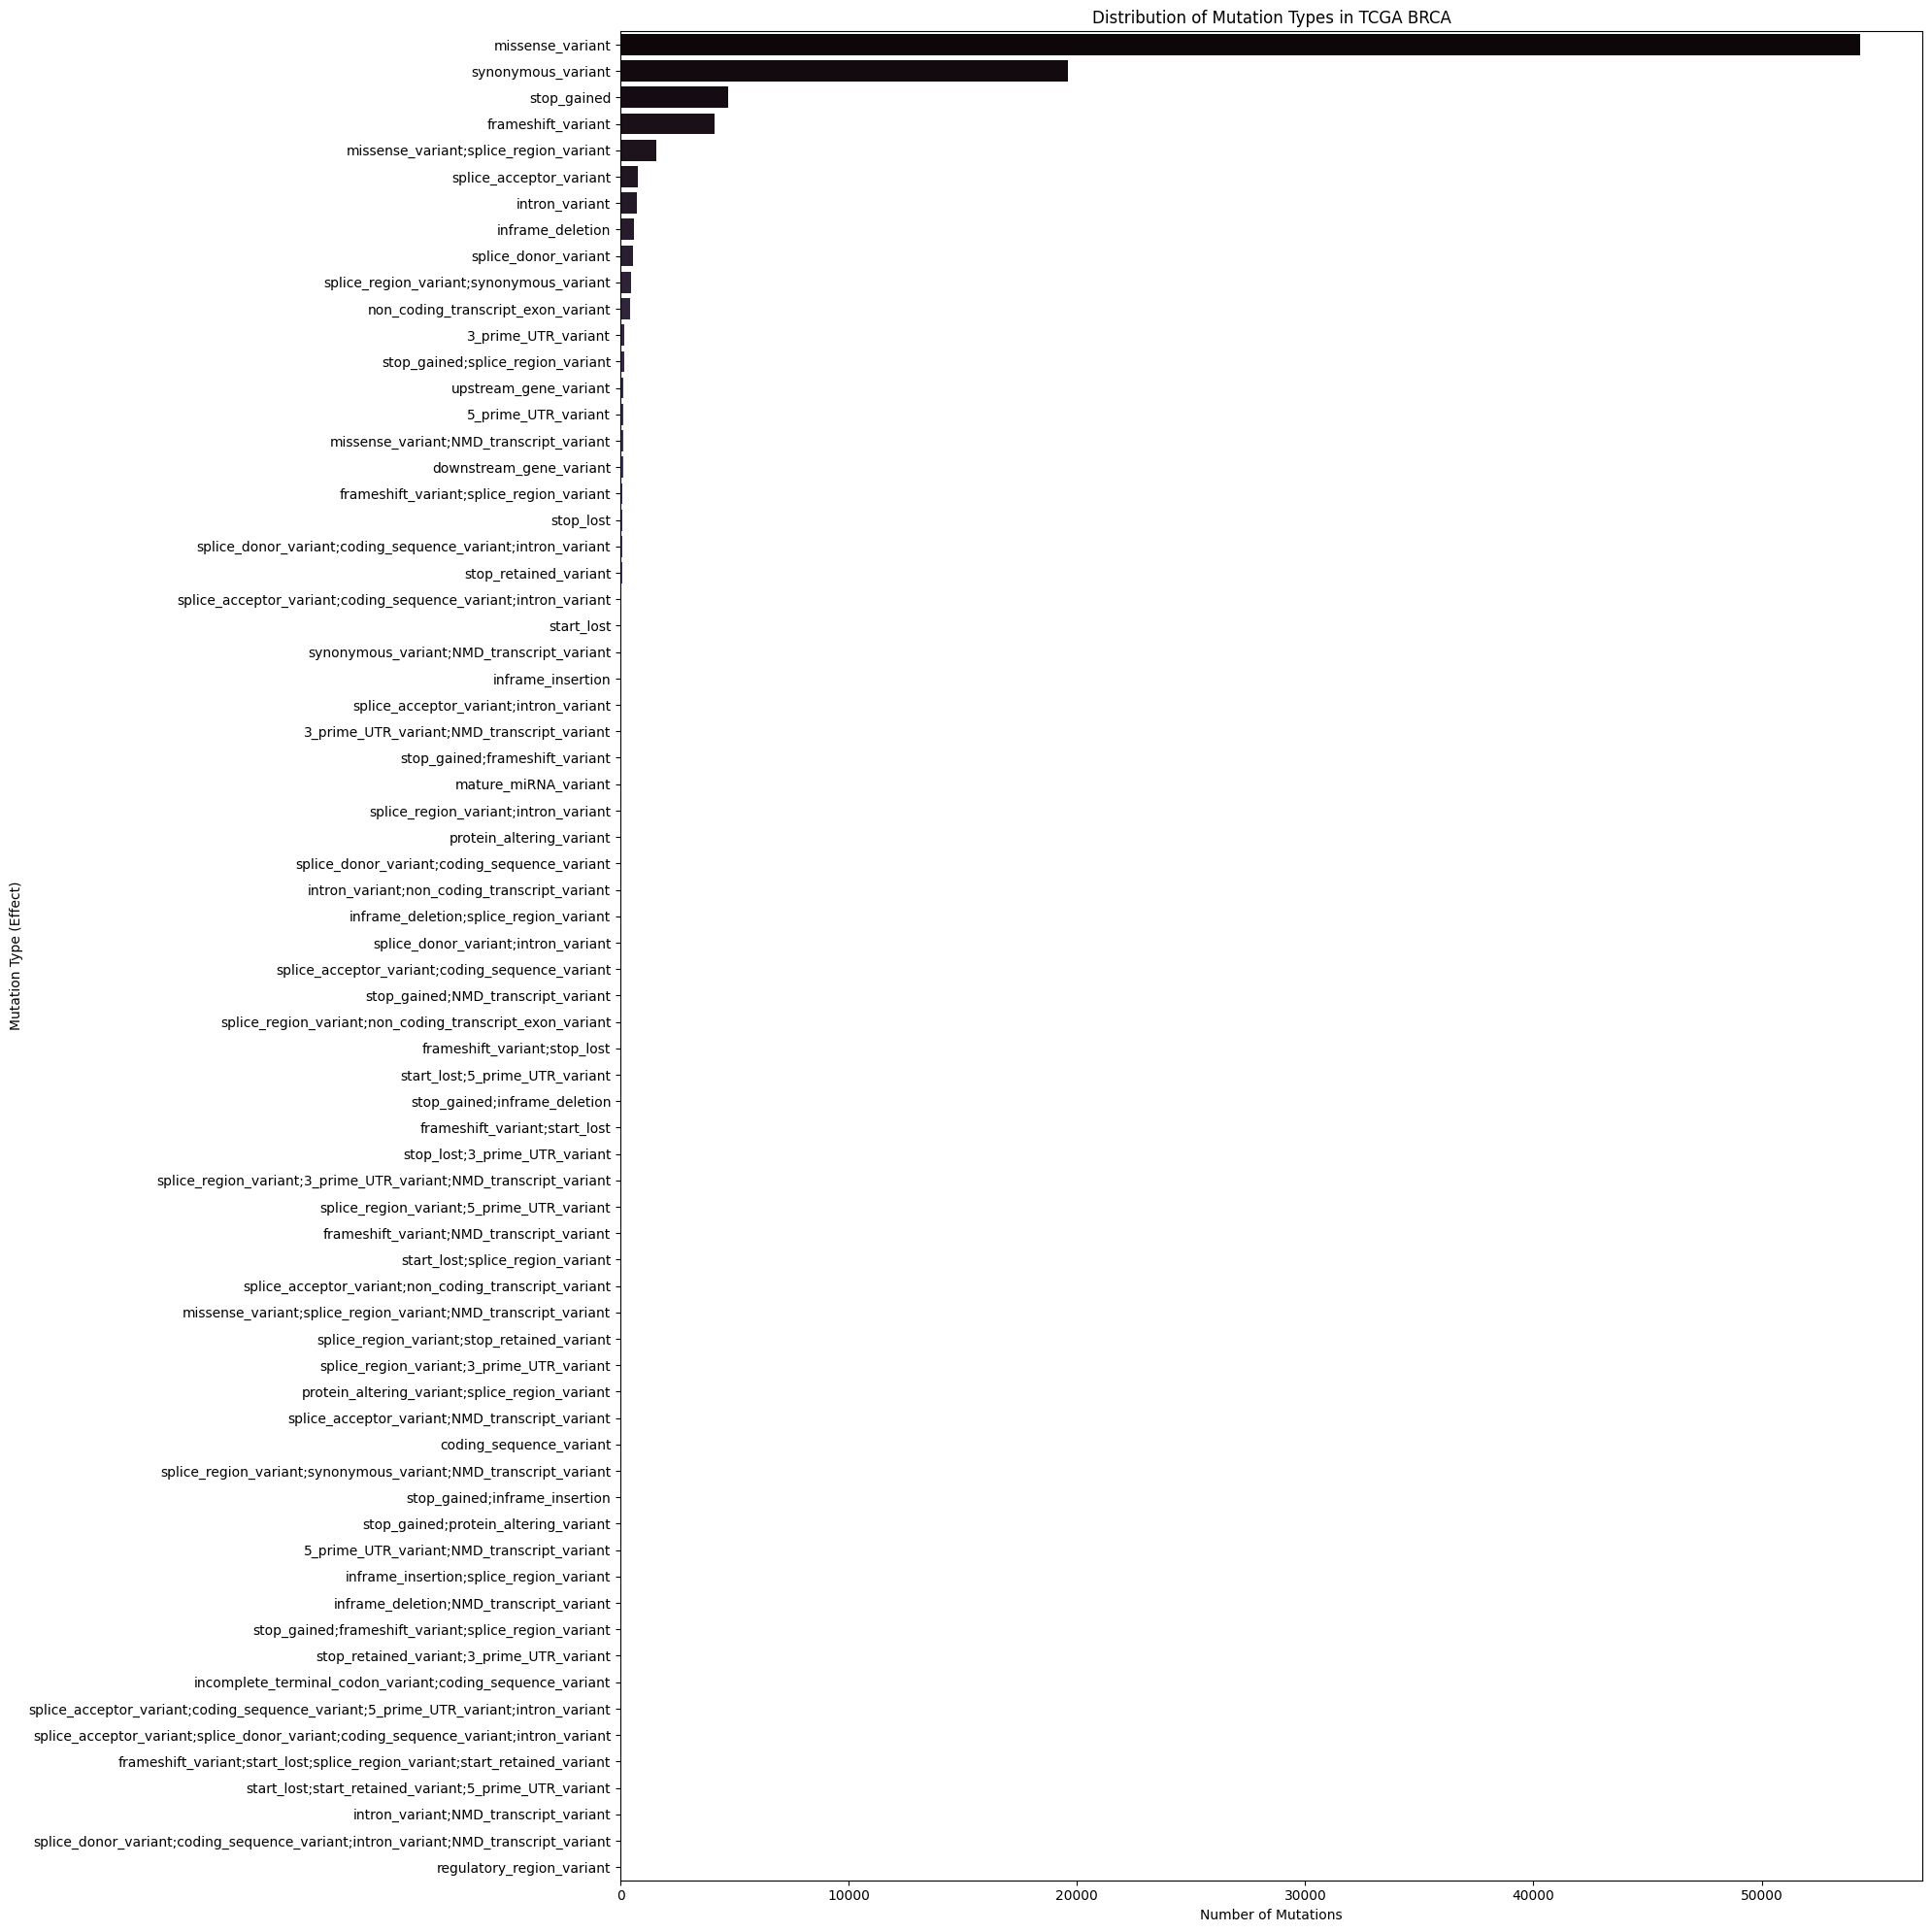

In [20]:
effect_counts = TCGA_BRCA['effect'].value_counts().reset_index()
effect_counts.columns = ['mutation_type', 'count']
effect_counts['percentage'] = (effect_counts['count'] / effect_counts['count'].sum()) * 100

display(effect_counts)


plt.figure(figsize=(20, 20))
sns.barplot(data=effect_counts, x='count', y='mutation_type', hue='mutation_type', legend=False, palette='mako')
plt.title('Distribution of Mutation Types in TCGA BRCA')
plt.xlabel('Number of Mutations')
plt.ylabel('Mutation Type (Effect)')
plt.tight_layout()
plt.show()

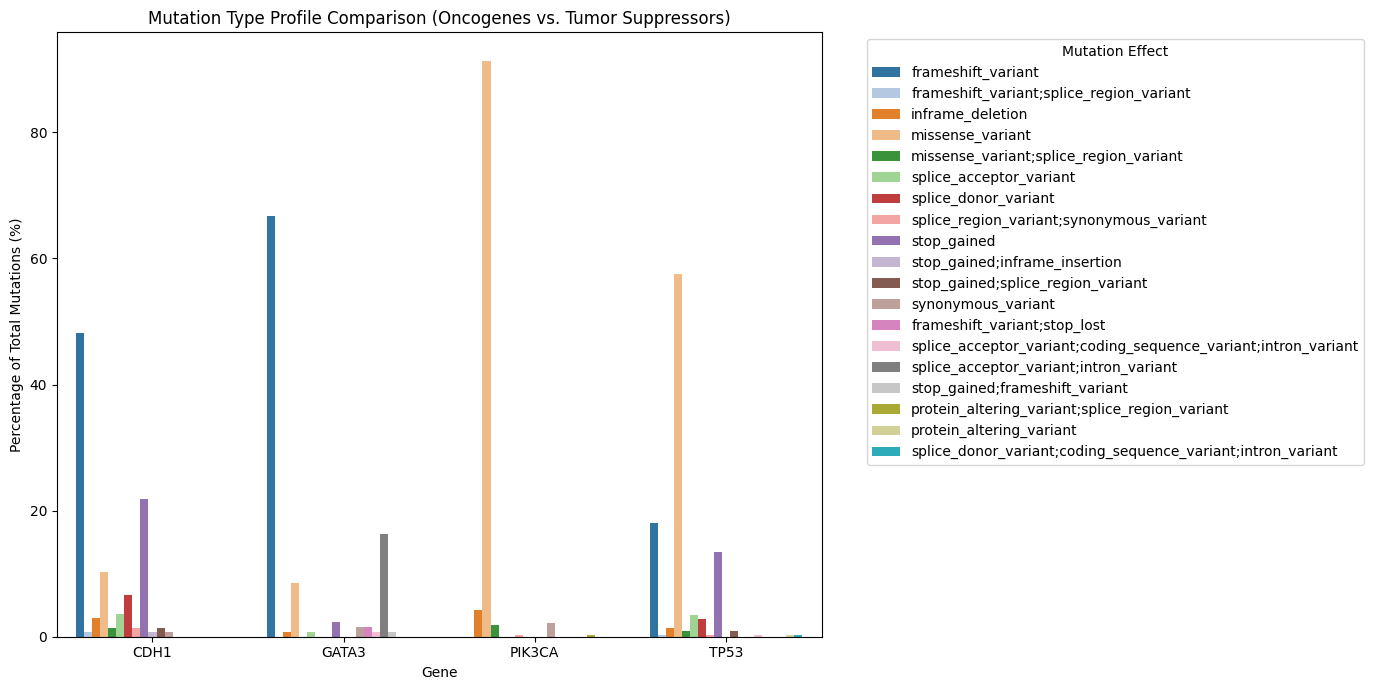

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Select key genes of interest (Oncogenes vs Tumor Suppressors)
selected_genes = ['PIK3CA', 'TP53', 'CDH1', 'GATA3']

# Filter dataset for these genes
df_filtered = TCGA_BRCA[TCGA_BRCA['gene'].isin(selected_genes)]

# Calculate counts of each mutation type (effect) per gene
gene_effect_counts = df_filtered.groupby(['gene', 'effect']).size().reset_index(name='count')

# Calculate percentages within each gene for fair comparison
gene_totals = df_filtered.groupby('gene').size().reset_index(name='total')
gene_effect_counts = gene_effect_counts.merge(gene_totals, on='gene')
gene_effect_counts['percentage'] = (gene_effect_counts['count'] / gene_effect_counts['total']) * 100

# Plot the comparison
plt.figure(figsize=(14, 7))
sns.barplot(
    data=gene_effect_counts,
    x='gene',
    y='percentage',
    hue='effect',
    palette='tab20'
)

plt.title('Mutation Type Profile Comparison (Oncogenes vs. Tumor Suppressors)')
plt.xlabel('Gene')
plt.ylabel('Percentage of Total Mutations (%)')
plt.legend(title='Mutation Effect', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [17]:
unique_effects = TCGA_BRCA['effect'].value_counts(dropna=False)
print("All unique values in the 'effect' column and their counts:")
display(unique_effects)

All unique values in the 'effect' column and their counts:


,count
effect,
missense_variant,54319
synonymous_variant,19614
stop_gained,4733
frameshift_variant,4126
missense_variant;splice_region_variant,1588
...,...
start_lost;start_retained_variant;5_prime_UTR_variant,1
intron_variant;NMD_transcript_variant,1
splice_donor_variant;coding_sequence_variant;intron_variant;NMD_transcript_variant,1


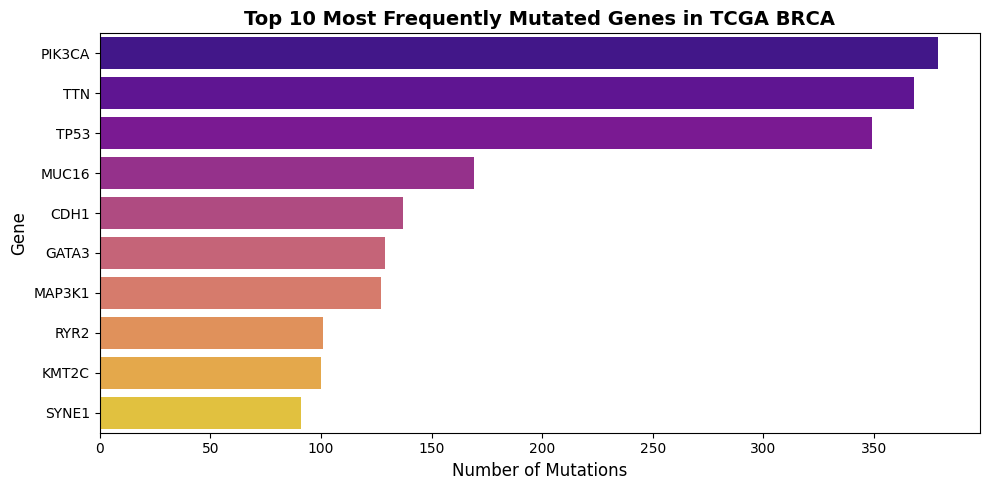

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns


gene_counts = TCGA_BRCA['gene'].value_counts().reset_index()
gene_counts.columns = ['gene', 'mutation_count']

top_10_genes = gene_counts.head(10)


plt.figure(figsize=(10, 5))
sns.barplot(
    data=top_10_genes,
    x='mutation_count',
    y='gene',
    hue='gene',
    legend=False,
    palette='plasma'
)

plt.title('Top 10 Most Frequently Mutated Genes in TCGA BRCA', fontsize=14, fontweight='bold')
plt.xlabel('Number of Mutations', fontsize=12)
plt.ylabel('Gene', fontsize=12)
plt.tight_layout()
plt.show()